In [ ]:
# Install required libraries
!pip install pandas numpy matplotlib seaborn scipy

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# Set graph style
sns.set_style("whitegrid")

print("Python environment is ready!")

Python environment is ready!


HOTEL BOOKINGS


Graph 1: Missing Values Heatmap (Raw Data Check)

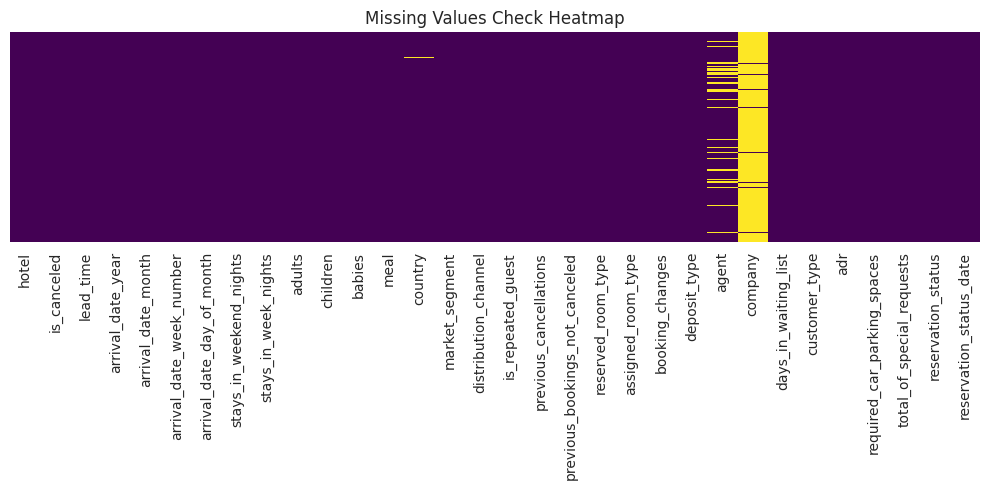

In [117]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Check Heatmap")
plt.tight_layout()
plt.show()

Graph 2: Multi-Boxplots (Outlier Detection for Top Numeric Columns)

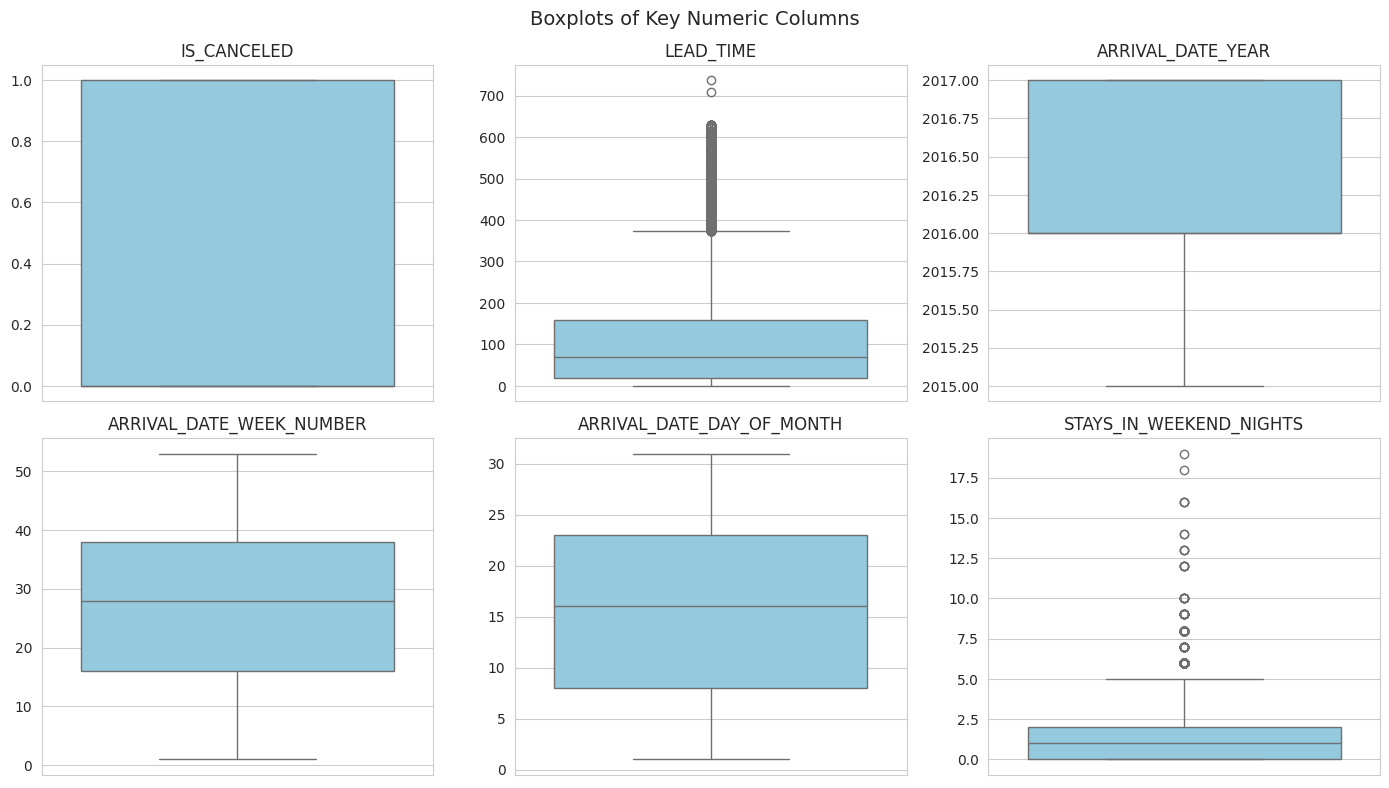

In [118]:
num_cols = df.select_dtypes(include=[np.number]).columns[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue")
    axes[i].set_title(col.upper())
    axes[i].set_ylabel("")
plt.suptitle("Boxplots of Key Numeric Columns", fontsize=14)
plt.tight_layout()
plt.show()

Graph 3: Bar Chart — First Categorical Column Count (e.g., Hotel Type)

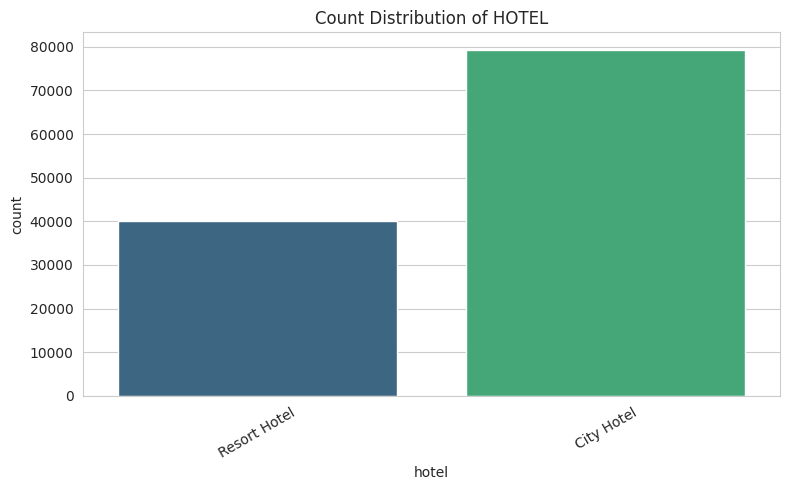

In [119]:
cat_col = df.select_dtypes(include=["object"]).columns[0]
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=cat_col, palette="viridis")
plt.title(f"Count Distribution of {cat_col.upper()}")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Graph 4: Pie Chart — Proportion of Top Categories

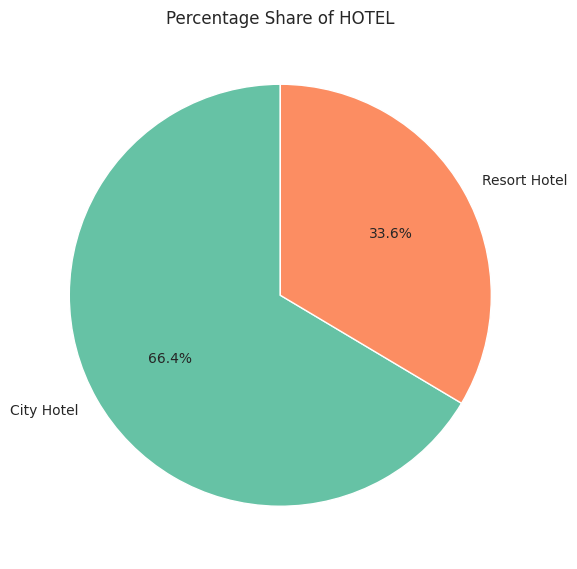

In [120]:
cat_col = df.select_dtypes(include=["object"]).columns[0]
counts = df[cat_col].value_counts().head(5)
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
plt.title(f"Percentage Share of {cat_col.upper()}")
plt.tight_layout()
plt.show()

Graph 5: Donut Chart — Market Segment / Second Category Share

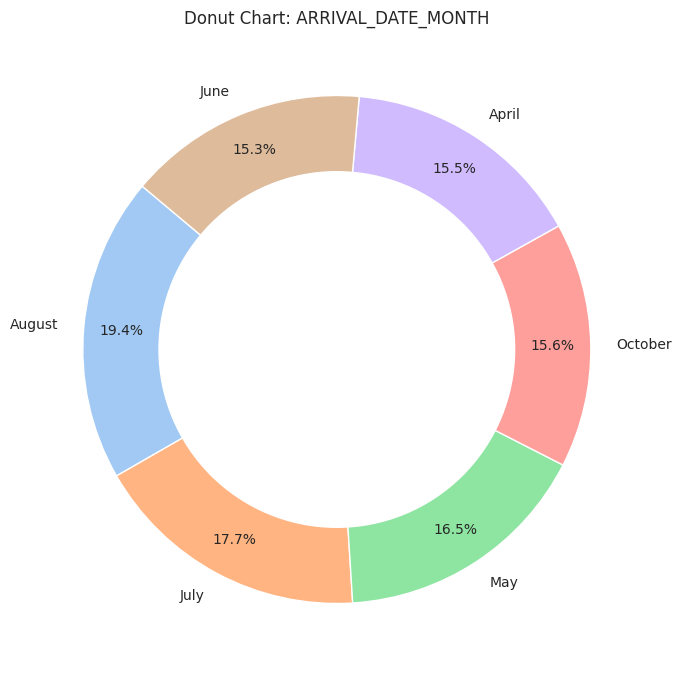

In [121]:
cat_cols = df.select_dtypes(include=["object"]).columns
col_to_plot = cat_cols[1] if len(cat_cols) > 1 else cat_cols[0]
counts = df[col_to_plot].value_counts().head(6)

plt.figure(figsize=(7, 7))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=140, pctdistance=0.85, colors=sns.color_palette("pastel"))
plt.gca().add_artist(plt.Circle((0, 0), 0.70, fc="white"))
plt.title(f"Donut Chart: {col_to_plot.upper()}")
plt.tight_layout()
plt.show()

Graph 6: Horizontal Bar Chart — Top 10 Frequent Values (e.g., Country)

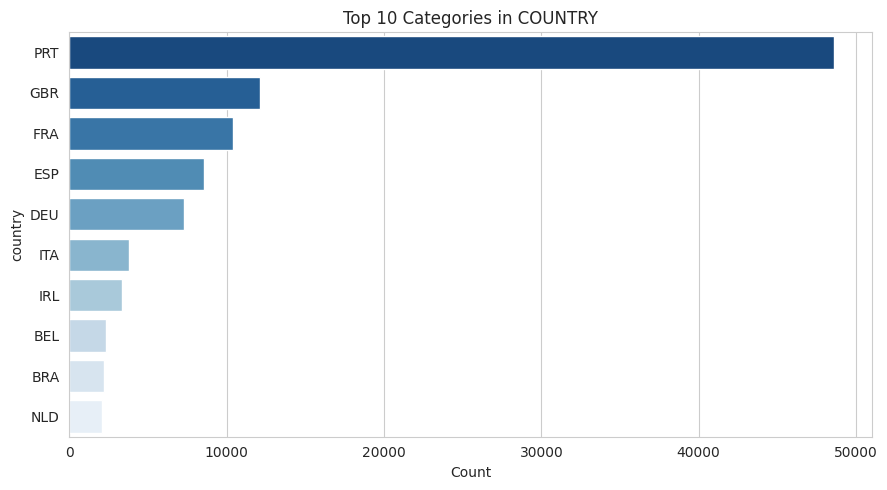

In [122]:
cat_cols = df.select_dtypes(include=["object"]).columns
col_to_plot = "country" if "country" in df.columns else cat_cols[-1]
top_10 = df[col_to_plot].value_counts().head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_10.values, y=top_10.index, palette="Blues_r")
plt.title(f"Top 10 Categories in {col_to_plot.upper()}")
plt.xlabel("Count")
plt.tight_layout()
plt.show()

Graph 7: Histogram with KDE Curve — Numeric Distribution (e.g., Lead Time / ADR)

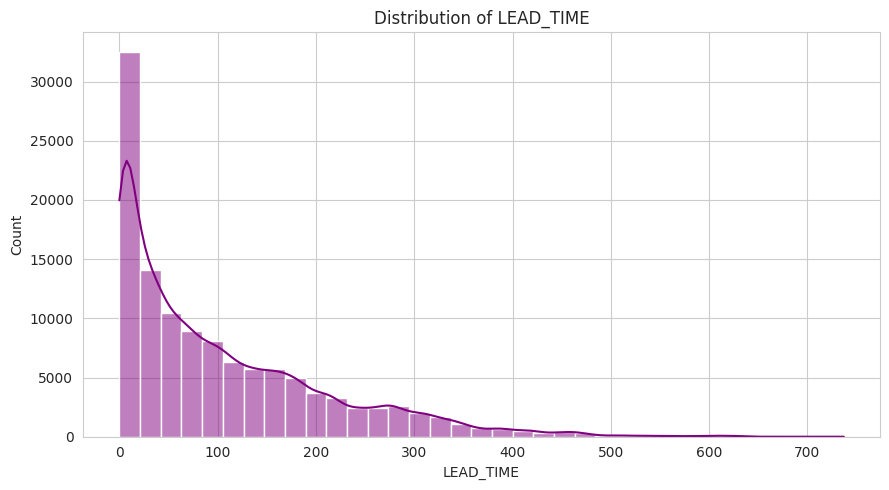

In [123]:
num_col = "lead_time" if "lead_time" in df.columns else df.select_dtypes(include=[np.number]).columns[0]
plt.figure(figsize=(9, 5))
sns.histplot(df[num_col], bins=35, kde=True, color="purple")
plt.title(f"Distribution of {num_col.upper()}")
plt.xlabel(num_col.upper())
plt.tight_layout()
plt.show()

Graph 8: KDE Density Plot — Comparing Two Groups

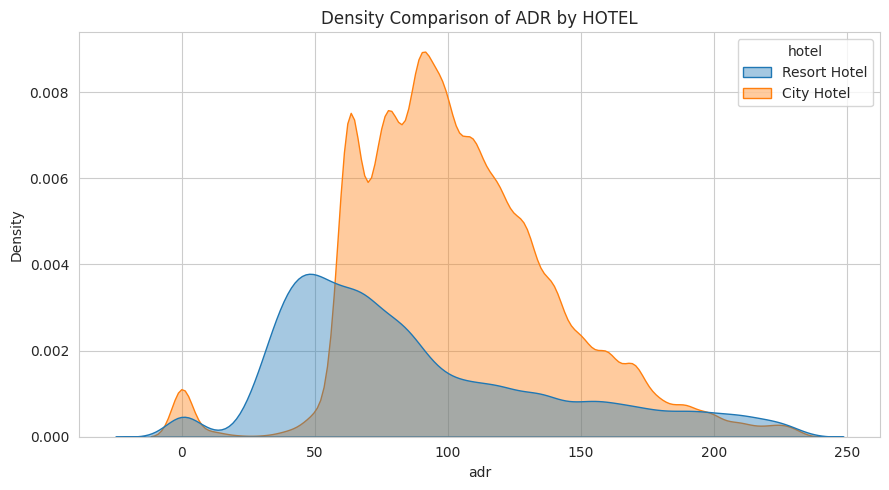

In [124]:
num_col = "adr" if "adr" in df.columns else df.select_dtypes(include=[np.number]).columns[-1]
cat_col = df.select_dtypes(include=["object"]).columns[0]
upper_limit = df[num_col].quantile(0.98)

plt.figure(figsize=(9, 5))
sns.kdeplot(data=df[df[num_col] <= upper_limit], x=num_col, hue=cat_col, fill=True, alpha=0.4)
plt.title(f"Density Comparison of {num_col.upper()} by {cat_col.upper()}")
plt.tight_layout()
plt.show()

Graph 9: Clustered Bar Chart — Comparing Two Categorical Columns

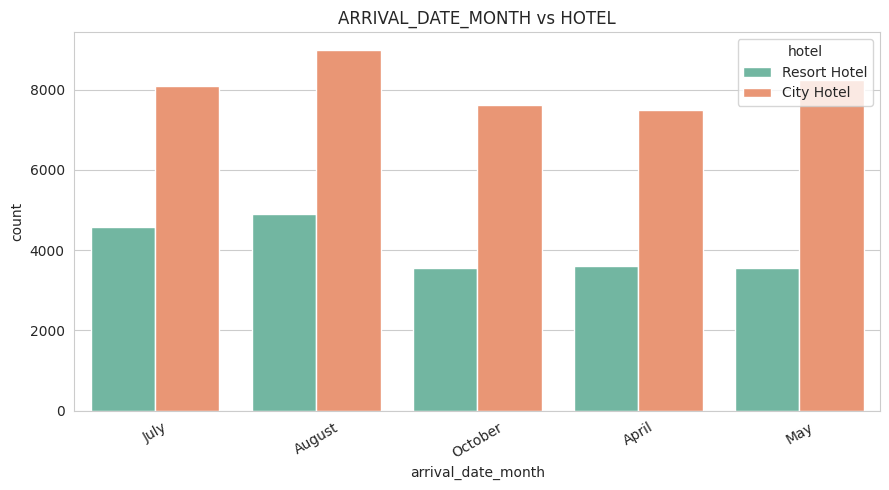

In [125]:
cat_cols = df.select_dtypes(include=["object"]).columns
c1 = cat_cols[0]
c2 = cat_cols[1] if len(cat_cols) > 1 else cat_cols[0]
top_c2 = df[c2].value_counts().head(5).index

plt.figure(figsize=(9, 5))
sns.countplot(data=df[df[c2].isin(top_c2)], x=c2, hue=c1, palette="Set2")
plt.title(f"{c2.upper()} vs {c1.upper()}")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Graph 10: 100% Stacked Bar Chart — Category Proportions

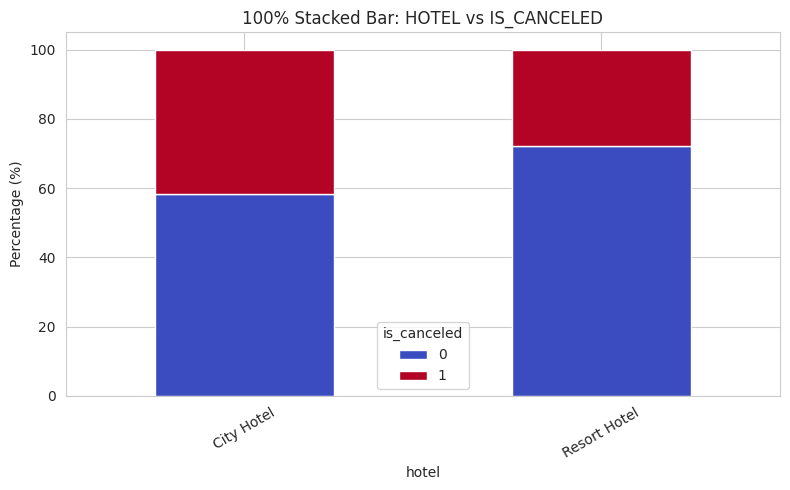

In [126]:
cat_cols = df.select_dtypes(include=["object"]).columns
c1 = cat_cols[0]
c2 = "is_canceled" if "is_canceled" in df.columns else (cat_cols[1] if len(cat_cols) > 1 else cat_cols[0])

ct = pd.crosstab(df[c1], df[c2], normalize="index") * 100
ct.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="coolwarm")
plt.title(f"100% Stacked Bar: {c1.upper()} vs {c2.upper()}")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Graph 11: Violin Plot — Category vs Numeric Spread

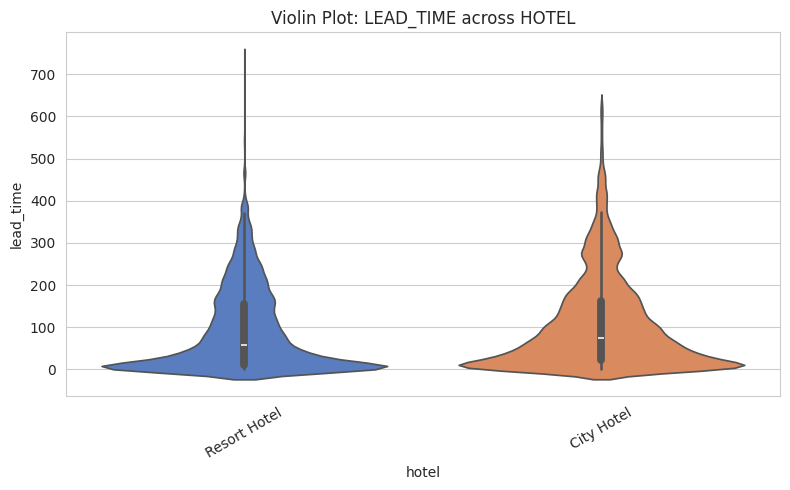

In [128]:
cat_col = df.select_dtypes(include=["object"]).columns[0]
num_col = "lead_time" if "lead_time" in df.columns else df.select_dtypes(include=[np.number]).columns[0]

plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x=cat_col, y=num_col, palette="muted")
plt.title(f"Violin Plot: {num_col.upper()} across {cat_col.upper()}")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Graph 12: Scatter Plot — Relationship Between Two Numeric Variables

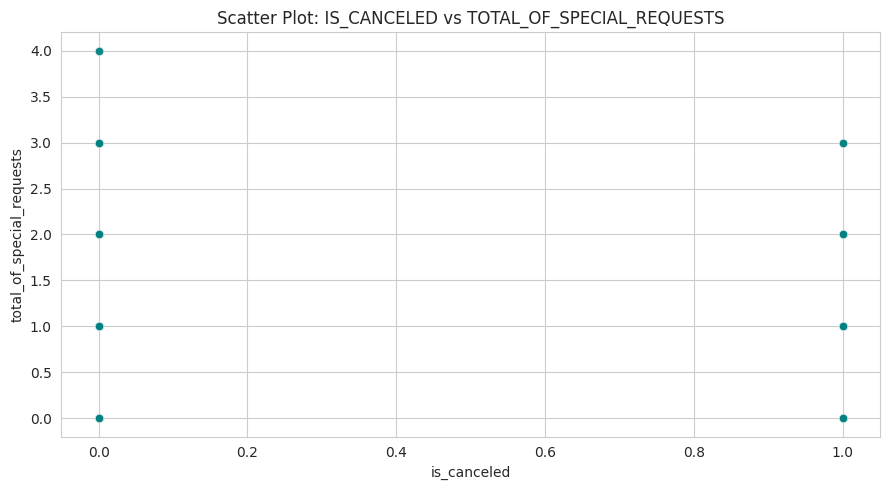

In [129]:
num_cols = df.select_dtypes(include=[np.number]).columns
x_col = num_cols[0]
y_col = num_cols[-1] if len(num_cols) > 1 else num_cols[0]
sample_df = df.sample(min(1500, len(df)), random_state=42)

plt.figure(figsize=(9, 5))
sns.scatterplot(data=sample_df, x=x_col, y=y_col, alpha=0.6, color="teal")
plt.title(f"Scatter Plot: {x_col.upper()} vs {y_col.upper()}")
plt.tight_layout()
plt.show()

Graph 13: Regression Line Plot (regplot) — Trend Analysis

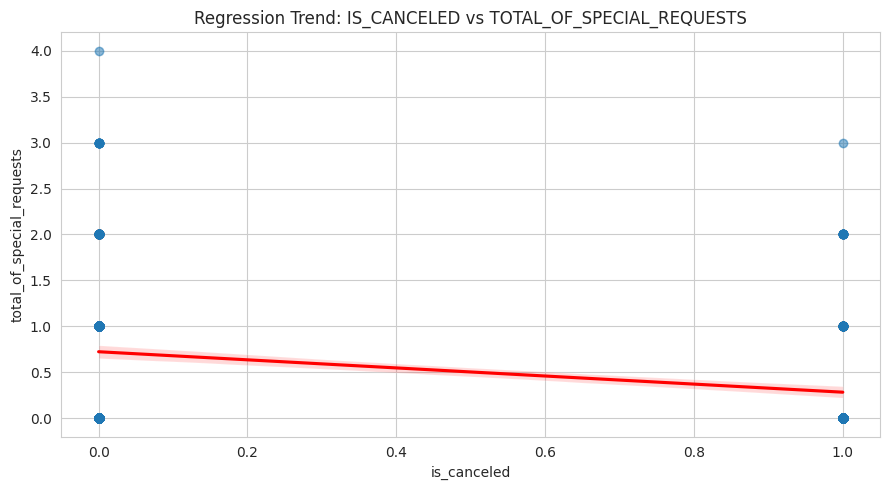

In [130]:
num_cols = df.select_dtypes(include=[np.number]).columns
x_col = num_cols[0]
y_col = num_cols[-1] if len(num_cols) > 1 else num_cols[0]
sample_df = df.sample(min(1000, len(df)), random_state=42)

plt.figure(figsize=(9, 5))
sns.regplot(data=sample_df, x=x_col, y=y_col, scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title(f"Regression Trend: {x_col.upper()} vs {y_col.upper()}")
plt.tight_layout()
plt.show()

Graph 14: ECDF Plot — Cumulative Distribution

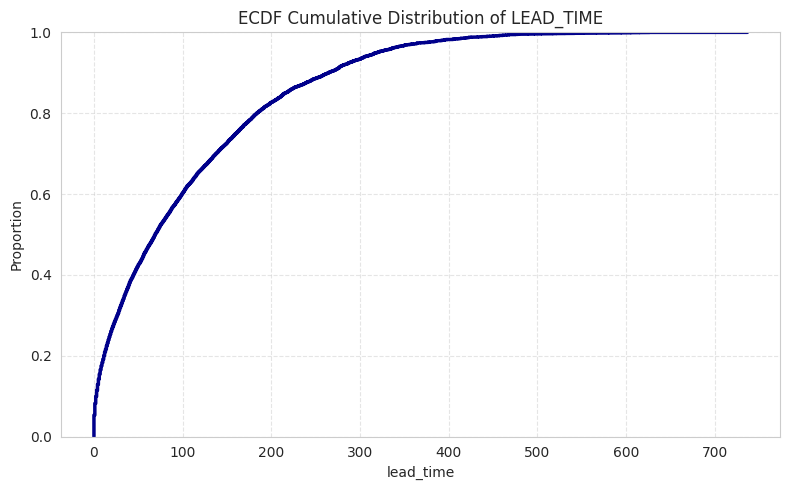

In [131]:
num_col = "lead_time" if "lead_time" in df.columns else df.select_dtypes(include=[np.number]).columns[0]
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x=num_col, linewidth=2.5, color="darkblue")
plt.title(f"ECDF Cumulative Distribution of {num_col.upper()}")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Graph 15: Correlation Heatmap of All Numeric Columns

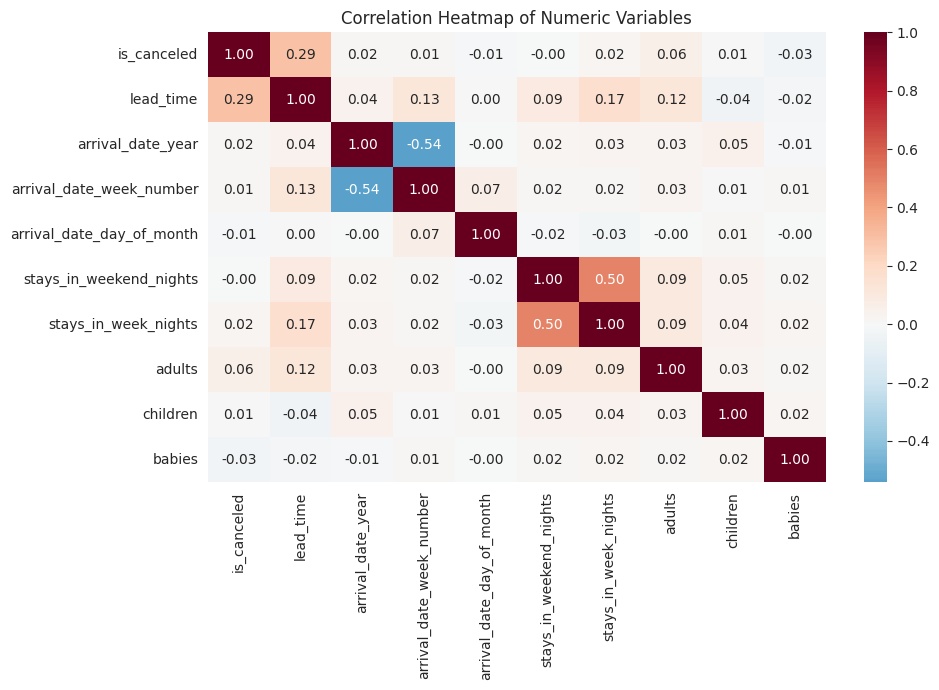

In [132]:
num_df = df.select_dtypes(include=[np.number]).iloc[:, :10]
plt.figure(figsize=(10, 7))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

Part 1: Loading Data & Basic Inspection


In [135]:
print("Dataset shape:", df.shape)

Dataset shape: (119390, 32)


In [136]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [137]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [139]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [140]:
df.describe().round(2)

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119386.0,119390.00,119390.00,119390.00,119390.00,119390.00,103050.00,6797.00,119390.00,119390.00,119390.00,119390.00
mean,0.37,104.01,2016.16,27.17,15.80,0.93,2.50,1.86,0.1,0.01,0.03,0.09,0.14,0.22,86.69,189.27,2.32,101.83,0.06,0.57
std,0.48,106.86,0.71,13.61,8.78,1.00,1.91,0.58,0.4,0.10,0.18,0.84,1.50,0.65,110.77,131.66,17.59,50.54,0.25,0.79
min,0.00,0.00,2015.00,1.00,1.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,1.00,6.00,0.00,-6.38,0.00,0.00
25%,0.00,18.00,2016.00,16.00,8.00,0.00,1.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,9.00,62.00,0.00,69.29,0.00,0.00
50%,0.00,69.00,2016.00,28.00,16.00,1.00,2.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,14.00,179.00,0.00,94.58,0.00,0.00
75%,1.00,160.00,2017.00,38.00,23.00,2.00,3.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,229.00,270.00,0.00,126.00,0.00,1.00
max,1.00,737.00,2017.00,53.00,31.00,19.00,50.00,55.00,10.0,10.00,1.00,26.00,72.00,21.00,535.00,543.00,391.00,5400.00,8.00,5.00


In [141]:
df.describe(include="object")

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [142]:
print("Total cells:", df.size)

Total cells: 3820480


In [143]:
print("Columns:", df.columns.tolist())

Columns: ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


Part 2: Python Data Structures — Lists, Tuples, Sets, Dictionaries

In [144]:
room_types = ["Single", "Double", "Twin", "Suite", "Deluxe", "Executive"]
print("Room Types List:", room_types)

Room Types List: ['Single', 'Double', 'Twin', 'Suite', 'Deluxe', 'Executive']


In [145]:
hotel_info = ("HTL01", "Grand Palace Hotel", "New Delhi")
print("Hotel Tuple:", hotel_info)

Hotel Tuple: ('HTL01', 'Grand Palace Hotel', 'New Delhi')


In [146]:
meal_plans = {"BB", "HB", "FB", "SC", "BB", "HB"}
print("Unique Meal Plans Set:", meal_plans)

Unique Meal Plans Set: {'HB', 'BB', 'FB', 'SC'}


In [147]:
room_tariff = {
    "Single": 3500,
    "Double": 5000,
    "Twin": 5200,
    "Suite": 12000,
    "Deluxe": 7500,
    "Executive": 9500
}
print("Room Tariff Dict:", room_tariff)

Room Tariff Dict: {'Single': 3500, 'Double': 5000, 'Twin': 5200, 'Suite': 12000, 'Deluxe': 7500, 'Executive': 9500}


In [149]:
unique_countries = set(country_list)
unique_segments = set(df["market_segment"].tolist())
print("Total Unique Countries:", len(unique_countries))
print("Market Segments:", unique_segments)

Total Unique Countries: 177
Market Segments: {'Offline TA/TO', 'Direct', 'Corporate', 'Aviation', 'Complementary', 'Groups', 'Online TA', 'Undefined'}


In [150]:
first_booking = df.iloc[0].to_dict()
print("First Booking Record:", first_booking)

First Booking Record: {'hotel': 'Resort Hotel', 'is_canceled': 0, 'lead_time': 342, 'arrival_date_year': 2015, 'arrival_date_month': 'July', 'arrival_date_week_number': 27, 'arrival_date_day_of_month': 1, 'stays_in_weekend_nights': 0, 'stays_in_week_nights': 0, 'adults': 2, 'children': 0.0, 'babies': 0, 'meal': 'BB', 'country': 'PRT', 'market_segment': 'Direct', 'distribution_channel': 'Direct', 'is_repeated_guest': 0, 'previous_cancellations': 0, 'previous_bookings_not_canceled': 0, 'reserved_room_type': 'C', 'assigned_room_type': 'C', 'booking_changes': 3, 'deposit_type': 'No Deposit', 'agent': nan, 'company': nan, 'days_in_waiting_list': 0, 'customer_type': 'Transient', 'adr': 0.0, 'required_car_parking_spaces': 0, 'total_of_special_requests': 0, 'reservation_status': 'Check-Out', 'reservation_status_date': '2015-07-01'}


In [151]:
first_5_bookings = df.head(5).to_dict("records")
print("3rd Booking Hotel:", first_5_bookings[2]["hotel"])

3rd Booking Hotel: Resort Hotel


In [152]:
print("First room:", room_types[0])
print("Last room:", room_types[-1])
print("First three rooms:", room_types[0:3])
print("Every 2nd room:", room_types[::2])

First room: Single
Last room: Executive
First three rooms: ['Single', 'Double', 'Twin']
Every 2nd room: ['Single', 'Twin', 'Deluxe']


In [154]:
print("Suite Price:", room_tariff.get("Suite"))
print("Penthouse Price:", room_tariff.get("Penthouse", "Room type not available"))

Suite Price: 12000
Penthouse Price: Room type not available


In [155]:
room_types.append("Presidential")
room_types.remove("Presidential")
try:
    hotel_info[2] = "Mumbai"
except TypeError as e:
    print("Tuple Error:", e)

Tuple Error: 'tuple' object does not support item assignment


Part 3: NumPy Operations & Pandas Data Manipulation

In [157]:
print("NumPy Mean Lead Time:", np.nanmean(lead_arr).round(2))
print("NumPy Median Lead Time:", np.nanmedian(lead_arr))
print("NumPy Std Dev Lead Time:", np.nanstd(lead_arr).round(2))

NumPy Mean Lead Time: 104.01
NumPy Median Lead Time: 69.0
NumPy Std Dev Lead Time: 106.86


In [158]:
print("ADR Percentiles:", np.nanpercentile(adr_arr, [25, 50, 75, 95]))

ADR Percentiles: [ 69.29   94.575 126.    193.5  ]


In [162]:
print("Cancellation Counts:\n", df["is_canceled"].value_counts())

Cancellation Counts:
 is_canceled
0    75166
1    44224
Name: count, dtype: int64


In [163]:
print("Deposit Type %:\n", (df["deposit_type"].value_counts(normalize=True) * 100).round(2))

Deposit Type %:
 deposit_type
No Deposit    87.65
Non Refund    12.22
Refundable     0.14
Name: proportion, dtype: float64


In [164]:
city_confirmed = df.loc[(df["hotel"] == "City Hotel") & (df["is_canceled"] == 0)]
print("Confirmed City Hotel bookings:", len(city_confirmed))

Confirmed City Hotel bookings: 46228


In [165]:
subset_iloc = df.iloc[10:21, 0:6]
print(subset_iloc)

           hotel  is_canceled  lead_time  arrival_date_year  \
10  Resort Hotel            1         23               2015   
11  Resort Hotel            0         35               2015   
12  Resort Hotel            0         68               2015   
13  Resort Hotel            0         18               2015   
14  Resort Hotel            0         37               2015   
15  Resort Hotel            0         68               2015   
16  Resort Hotel            0         37               2015   
17  Resort Hotel            0         12               2015   
18  Resort Hotel            0          0               2015   
19  Resort Hotel            0          7               2015   
20  Resort Hotel            0         37               2015   

   arrival_date_month  arrival_date_week_number  
10               July                        27  
11               July                        27  
12               July                        27  
13               July                      

In [166]:
yearly_summary = df.groupby("arrival_date_year").agg(
    Total_Bookings=("hotel", "count"),
    Total_Revenue=("total_revenue", "sum"),
    Avg_ADR=("adr", "mean")
).round(2)
print(yearly_summary)

                   Total_Bookings  Total_Revenue  Avg_ADR
arrival_date_year                                        
2015                        21996     6818116.56    87.18
2016                        56707    18870601.20    98.33
2017                        40687    17034779.77   114.64


In [167]:
print((df.groupby("deposit_type")["is_canceled"].mean() * 100).round(2))

deposit_type
No Deposit    28.38
Non Refund    99.36
Refundable    22.22
Name: is_canceled, dtype: float64


In [168]:
ct_status = pd.crosstab(df["hotel"], df["reservation_status"])
print(ct_status)

reservation_status  Canceled  Check-Out  No-Show
hotel                                           
City Hotel             32186      46228      916
Resort Hotel           10831      28938      291


In [170]:
monthly_bookings = df.groupby(["arrival_month_num", "arrival_date_month"]).size()
print(monthly_bookings)

arrival_month_num  arrival_date_month
1                  January                5929
2                  February               8068
3                  March                  9794
4                  April                 11089
5                  May                   11791
6                  June                  10939
7                  July                  12661
8                  August                13877
9                  September             10508
10                 October               11160
11                 November               6794
12                 December               6780
dtype: int64


In [172]:
print((df.groupby("is_repeated_guest")["is_canceled"].mean() * 100).round(2))

is_repeated_guest
0    37.79
1    14.49
Name: is_canceled, dtype: float64
